   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Quality  \
0             Ye

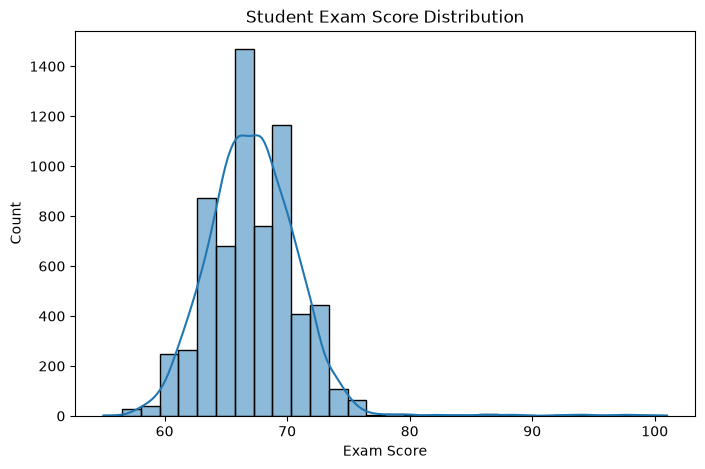

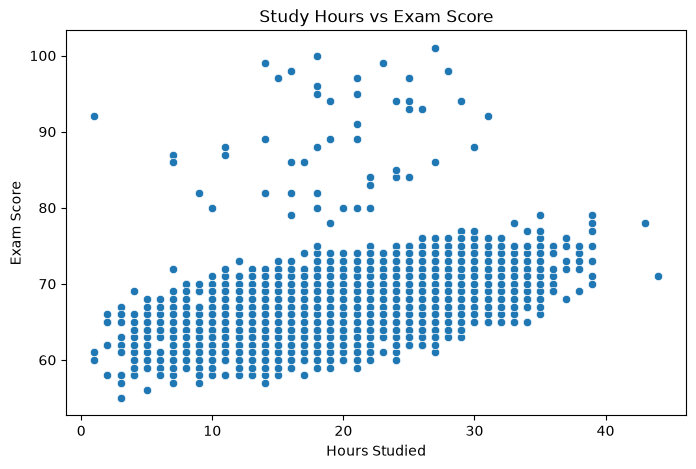

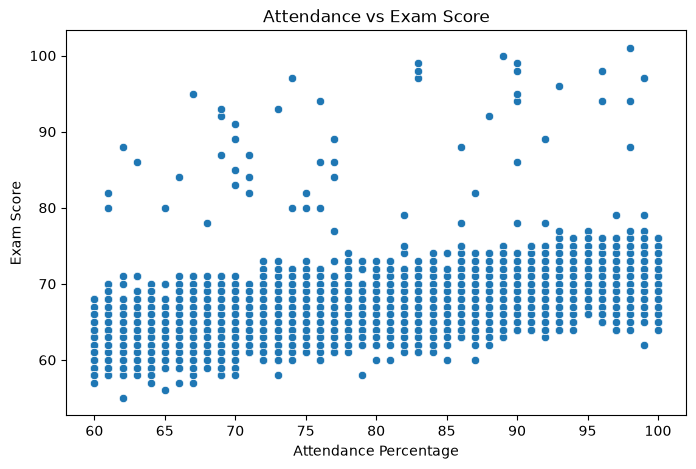

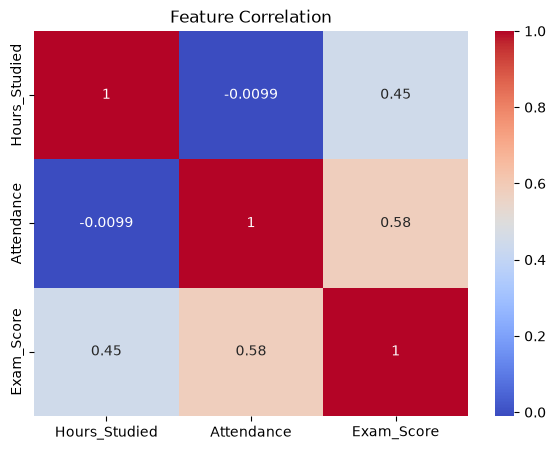


Training data
(5285, 2)

Testing data
(1322, 2)

Model trained successfully

Model Performance
MAE: 1.4689640272451197
MSE: 5.809117224063618
RMSE: 2.41021103309723
R2 Score: 0.589028125951463

Actual vs Predicted Marks
   Actual Marks  Predicted Marks
0            65        65.463827
1            65        66.041693
2            71        69.721435
3            64        67.121040
4            66        64.165290
5            66        67.340230
6            72        70.772552
7            66        69.199197
8            70        69.954740
9            70        68.872072


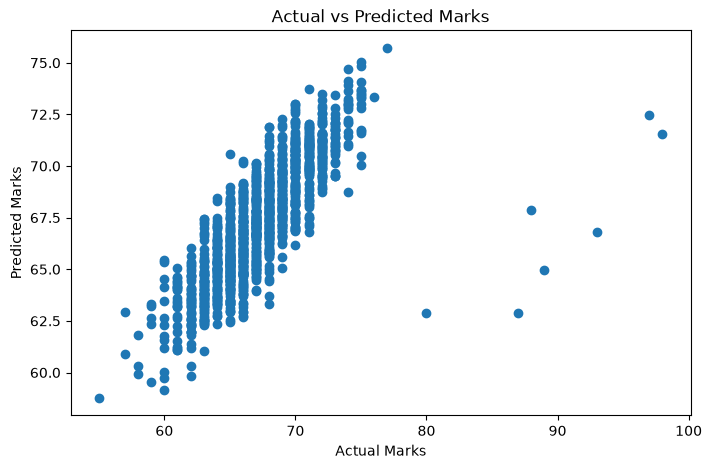

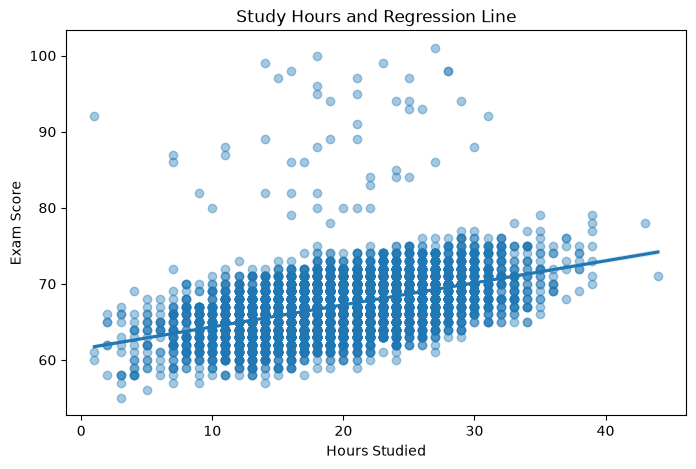


Model saved successfully

New Student Details
Study Hours: 5
Attendance: 85%

Predicted Exam Marks:
63.91

Project completed successfully


In [1]:

# Student Marks Prediction using Linear Regression

# importing libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import joblib


# loading dataset

df = pd.read_csv("StudentPerformanceFactors.csv")

print(df.head())

print("\nDataset shape")

print(df.shape)

print("\nDataset information")

df.info()

print("\nStatistical summary")

print(df.describe())


# checking missing values

print("\nMissing values")

print(df.isnull().sum())


# checking duplicate values

print("\nDuplicate values")

print(df.duplicated().sum())


# removing duplicate records

df.drop_duplicates(inplace=True)


# selecting required columns

df = df[
    [
        "Hours_Studied",
        "Attendance",
        "Exam_Score"
    ]
]


# removing missing values

df.dropna(inplace=True)


# checking data after cleaning

print("\nCleaned data")

print(df.head())

print(df.shape)


# EDA - exam score distribution

plt.figure(figsize=(8,5))

sns.histplot(df["Exam_Score"], bins=30, kde=True)

plt.title("Student Exam Score Distribution")

plt.xlabel("Exam Score")

plt.show()


# study hours vs marks

plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df["Hours_Studied"],
    y=df["Exam_Score"]
)

plt.title("Study Hours vs Exam Score")

plt.xlabel("Hours Studied")

plt.ylabel("Exam Score")

plt.show()


# attendance vs marks

plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df["Attendance"],
    y=df["Exam_Score"]
)

plt.title("Attendance vs Exam Score")

plt.xlabel("Attendance Percentage")

plt.ylabel("Exam Score")

plt.show()


# correlation heatmap

plt.figure(figsize=(7,5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")

plt.show()


# selecting input and output

X = df[
    [
        "Hours_Studied",
        "Attendance"
    ]
]

y = df["Exam_Score"]


# splitting training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


print("\nTraining data")

print(X_train.shape)

print("\nTesting data")

print(X_test.shape)


# creating Linear Regression model

model = LinearRegression()


# training model

model.fit(X_train, y_train)

print("\nModel trained successfully")


# predicting test data

y_pred = model.predict(X_test)


# model evaluation

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("\nModel Performance")

print("MAE:", mae)

print("MSE:", mse)

print("RMSE:", rmse)

print("R2 Score:", r2)


# actual vs predicted values

result = pd.DataFrame({

    "Actual Marks": y_test.values,

    "Predicted Marks": y_pred

})

print("\nActual vs Predicted Marks")

print(result.head(10))


# actual vs predicted graph

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")

plt.ylabel("Predicted Marks")

plt.title("Actual vs Predicted Marks")

plt.show()


# regression line for study hours

plt.figure(figsize=(8,5))

sns.regplot(
    x=df["Hours_Studied"],
    y=df["Exam_Score"],
    scatter_kws={"alpha": 0.4}
)

plt.title("Study Hours and Regression Line")

plt.xlabel("Hours Studied")

plt.ylabel("Exam Score")

plt.show()


# saving model

joblib.dump(model, "student_marks_model.pkl")

print("\nModel saved successfully")


# predicting marks for a new student

new_student = pd.DataFrame({

    "Hours_Studied": [5],

    "Attendance": [85]

})


prediction = model.predict(new_student)


print("\nNew Student Details")

print("Study Hours: 5")

print("Attendance: 85%")


print("\nPredicted Exam Marks:")

print(round(prediction[0], 2))


print("\nProject completed successfully")
